# Embedding (KAN-97, KAN-221, KAN-99)
Gözde Nur Özdemir · ELIZA · Sprint 2

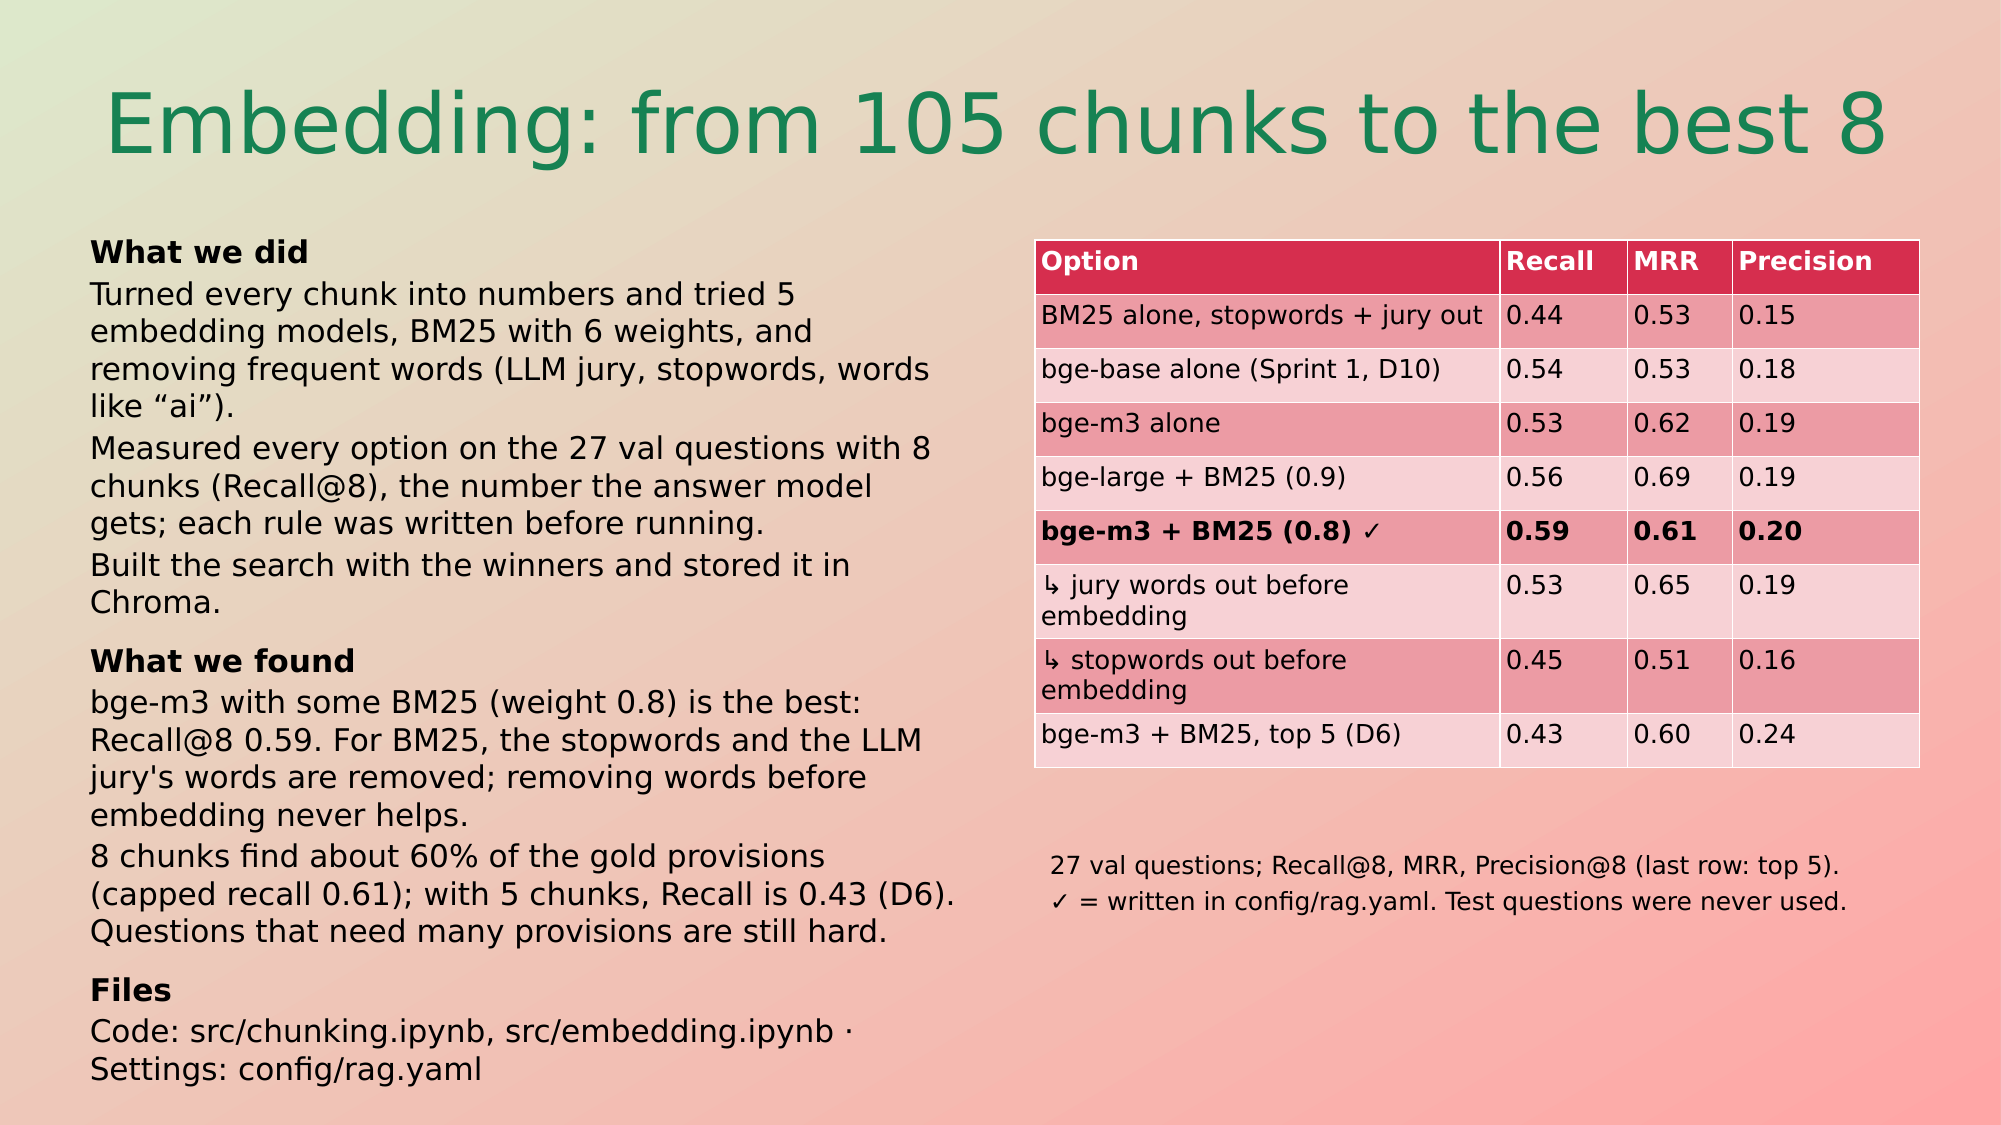

**What this notebook does:** The chunking notebook cut the AI Act into 105 chunks. Here I turn each chunk into numbers (embedding), so a question can find the chunks closest to it in meaning.

- **Part 1 (steps 1–7):** I try different settings and keep the best one.
- **Part 2 (steps 8–11):** I build the search with the best settings.

Words are never removed from the chunks themselves, because the answer must show the full text of the law.

| Step | Question | Source |
|---|---|---|
| 1 | Which questions, and how do I score? | instructor's slides: *"compute Recall@k / MRR on gold IDs"* |
| 2 | Should words be removed? | Dickinson 2026, *Stop Removing Stopwords* |
| 3 | How much do frequent words count? | BM25 weights (IDF) |
| 4 | Which frequent words are useless? (LLM jury) | instructor's feedback; Verga et al. 2024 |
| 5 | Does removing them help keyword search? | Dickinson 2026 |
| 6 | Which embedding model? Add keyword search? | D10, D12; my earlier retrieval project |
| 6b | Does removing them before embedding help? | extra experiment |
| 7 | How many chunks? (3, 5 or 8) | |
| 8–11 | Build the search and look at the results | |

**How I decide:** I write the rule first, measure every option on the same `val` questions, and keep the winner.

**What I expected and what I found:**
1. In Sprint 1 we chose bge-base on paper, with hybrid search.
2. With 8 chunks, **bge-m3** with some BM25 (dense weight 0.8) is the best: Recall@8 0.59, MRR 0.61. bge-base gets 0.55.
3. BM25 works best with the stopwords and the LLM jury's words removed (Recall@8 0.37 → 0.44).
4. Removing words before embedding never helps, so the embedding model reads the full text.
5. **8 chunks** come back. Recall@5 of the chosen search, which D6 asks for, is 0.43.

**Change of 10/11/2026:** every choice is now scored at **8 chunks** (Recall@8), the number of chunks the answer model gets. In the run of 09/11 the model was chosen at 5 chunks and the number of chunks after it, so the model was not chosen for the setting the system uses. Recall@5 is still reported, because D6 asks for it.

**Questions used:** only the `val` questions that have gold provisions (27). The `test` questions are never used here. Every question used before (Sprint 1 spike, earlier tuning) is in `val`; the split is explained in `src/split.ipynb`.

**How to run:** In Colab, *File → Upload notebook*, choose *Runtime → Change runtime type → T4 GPU*, then *Runtime → Run all*. The GPU is needed for the LLM jury in step 4 (about 20–30 minutes in total). On your own computer, open it from the `src/` folder of the repository.

## The experiment
Everything I try is listed in this cell. `config/rag.yaml` only keeps the chosen settings.

In [1]:
JURY = ["qwen3:14b", "phi4:14b", "gemma3:12b"]                 # step 4: three families, 12-14B, run on a free Colab T4 GPU
EMBEDDING_MODELS = ["sentence-transformers/all-MiniLM-L6-v2", "BAAI/bge-small-en-v1.5", "BAAI/bge-base-en-v1.5",
                    "BAAI/bge-large-en-v1.5", "BAAI/bge-m3"]       # step 6: the D10 options and two larger models
DENSE_WEIGHTS = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]                   # step 6: 0.5 = plain RRF, 1.0 = dense only
TOP_K = [3, 5, 8]                                                # step 7, D12
K = max(TOP_K)      # every choice is scored at 8 chunks, the number of chunks the answer model gets (Recall@8)

**Install once, in the terminal** (not in the notebook), in the same Python environment as Jupyter:
```
pip install sentence-transformers chromadb rank_bm25 pandas pyyaml requests scikit-learn umap-learn matplotlib
```

In [2]:
# Only in Google Colab: get the repository, install the libraries and Ollama, and download the three jury models

import os, subprocess, sys, time
if "google.colab" in sys.modules:
    REPO = "/content/ELIZA_DI502_ORGANIZATION"
    if not os.path.exists(REPO):
        subprocess.run(["git", "clone", "-q", "https://github.com/ELIZA-DI502/ELIZA_DI502_ORGANIZATION.git", REPO], check=True)
        subprocess.run("pip -q install sentence-transformers chromadb rank_bm25 umap-learn", shell=True, check=True)
    os.chdir(REPO + "/src")
    if subprocess.run("which ollama", shell=True, capture_output=True).returncode:      # install Ollama once
        subprocess.run("apt-get -qq install -y zstd > /dev/null; curl -fsSL https://ollama.com/install.sh | sh > /dev/null", shell=True, check=True)
    subprocess.Popen(["ollama", "serve"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    time.sleep(5)
    for m in JURY:
        print("Downloading", m); subprocess.run(["ollama", "pull", m], check=True, capture_output=True)

# Part 1 · Choose the settings

## 1. Which questions, and how do I score?
Every question has its **gold provisions** (`gold_ids`): the provisions that answer it.
- **Recall@k:** how many of the gold provisions are in the top k chunks. 2 of 4 found = 0.5.
- **Capped Recall@k:** the same, but a question with more than k gold provisions can still reach 1. Some questions have up to 26 gold provisions (BEIR benchmark, Thakur et al. 2021).
- **MRR:** how high the first correct chunk is (1 = first place).
- **Precision@k:** how many of the top k chunks are correct.

**k = 8 for every choice.** The answer model gets 8 chunks, so every setting is chosen by how it does with 8 chunks (Recall@8). Recall@5 is reported as well, because D6 asks for it.

In [3]:
import csv, json, os, re
from collections import Counter
import numpy as np, pandas as pd, requests, yaml
pd.set_option("display.max_colwidth", None)
np.random.seed(42)

HOME = os.path.expanduser("~")
try:
    here = os.getcwd()
except OSError:                                     # the folder this notebook was started in was deleted or is blocked
    os.chdir(HOME)
    here = HOME

def readable(folder):
    """True if rag.yaml in this folder can be opened (macOS can block Downloads, Desktop and Documents)."""
    try:
        open(os.path.join(folder, "rag.yaml")).close()
        return True
    except OSError:
        return False

IN_REPO = os.path.exists("../config/rag.yaml")      # opened from src/ in the repository
places = [here] + [os.path.join(HOME, p, "ELIZA") for p in ["", "Downloads", "Desktop", "Documents"]]
FOLDER = next((f for f in places if readable(f)), None)
assert IN_REPO or FOLDER, f"rag.yaml not found or blocked. Move the ELIZA folder into your home folder: {HOME}"
print("Files read from:", "the repository" if IN_REPO else "the ELIZA folder")      # no personal path in the output
P = lambda path: path if IN_REPO else os.path.join(FOLDER, os.path.basename(path))
CONFIG = yaml.safe_load(open(P("../config/rag.yaml")))
chunks = [json.loads(line) for line in open(P("../data/chunks.jsonl"), encoding="utf-8")]
questions = {r["id"]: r for r in csv.DictReader(open(P("../docs/eval/eval-set-v1.csv"), encoding="utf-8-sig"))}
ref_of = {c["chunk_id"]: c["ref"] for c in chunks}
words = lambda text: re.findall(r"[a-z0-9]+", text.lower())
print(len(chunks), "chunks,", len(questions), "questions")
dev = [q for q in questions.values() if q["split"] == "val" and q["gold_ids"].strip()]   # val questions that have gold provisions (KAN-53)
print(len(dev), "val questions with gold provisions are scored")

def score(search, k=K):
    """Recall@k, capped Recall@k, MRR and Precision@k over the val questions, on gold provision IDs (gold_ids)."""
    recall, capped, rr, precision = [], [], [], []
    for q in dev:
        gold = set(q["gold_ids"].split(";"))
        found = [c.split("#")[0] for c in search(q["question"])[:k]]   # chunk ID -> provision ID (ART13-3#2 -> ART13-3)
        hits = len(gold & set(found))
        recall.append(hits / len(gold))
        capped.append(hits / min(k, len(gold)))                       # a question with more than k gold provisions can still reach 1
        rr.append(next((1 / n for n, p in enumerate(found, 1) if p in gold), 0))
        precision.append(np.mean([p in gold for p in found]))
    return {f"Recall@{k}": round(np.mean(recall), 2), f"Capped recall@{k}": round(np.mean(capped), 2),
            "MRR": round(np.mean(rr), 2), f"Precision@{k}": round(np.mean(precision), 2)}

pd.DataFrame(dev)[["id", "question", "gold_ids"]]

Files read from: the repository
105 chunks, 46 questions
27 val questions with gold provisions are scored


,id,question,gold_ids
0,A-01,"What does the AI Act require for the training, validation and testing data sets and the logging of a high-risk AI system used for student admissions?",ART10-2;ART10-3;ART10-4;ART12-1;ART12-2
1,A-02,And what must the people who oversee it be able to do?,ART14-4
2,A-05,"Our platform decides which applicants are admitted to our university programmes, using their transcripts, standardised test scores and socio-economic data. Which AI Act provisions relate to it?",ANX3-3-a;ART6-2;ART6-3-3
3,A-06,"Our tool does not decide admissions. It only prepares a short summary of each application for the admission committee, which then assesses every applicant itself. Is there an exception under which it is not high-risk, and what are its conditions?",ART6-3-1;ART6-3-d;ART6-3-3
4,B-01,We made an AI-based tool that only takes the grades teachers already gave and calculates the weighted average. Is this still a high-risk AI system?,ART6-2;ART6-3-1;ART6-3-a;ART6-3-3
5,B-03,"Okay, and if we decide our grade calculator is not high-risk, do we still have to do anything before we launch it?",ART6-4;ART49-2
6,B-04,"Does the AI Act's prohibition on AI systems that infer emotions in education institutions apply to a webcam feature that detects whether students are bored or frustrated during an online lesson, and is there an exception?",ART5-1-f
7,B-05,As the product manager I need a checklist: which requirements does the AI Act set for a high-risk AI system that grades students' work?,ART8-1;ART9-1;ART10-1;ART11-1;ART12-1;ART13-1;ART13-2;ART14-1;ART15-1
8,B-06,We plan to launch an AI tool that marks students' essays and gives each one a score. From what date do the AI Act's high-risk rules apply to a tool like this?,ART113-3-c-i;ANX3-3-b
9,B-07,I'm on the compliance team. I read that an AI system that evaluates learning outcomes is only high-risk if it also steers the learning process. Is that right?,ANX3-3-b;ART6-2


## 2. Should words be removed?
The embedding model reads full sentences. Small words can change a rule: *"shall **not** be considered high-risk"* means the opposite without "not".

Keyword search (BM25) only looks at single words. A 2026 study on legal texts (Dickinson, *Stop Removing Stopwords*) found that removing stopwords usually does not help, and says *"the burden of proof sits with removal"*. So nothing is removed by default, but I still test it (steps 5 and 6b).

In [4]:
example = next(c for c in chunks if c["chunk_id"] == "ART6-3-1")
print("TEXT:", example["text"][:150], "...")
print("BM25:", words(example["text"])[:18], "...")
print(sum(any(w in {"not", "no", "nor"} for w in words(c["text"])) for c in chunks), "of 105 chunks contain a negation")

TEXT: 3. By derogation from paragraph 2, an AI system referred to in Annex III shall not be considered to be high-risk where it does not pose a significant  ...
BM25: ['3', 'by', 'derogation', 'from', 'paragraph', '2', 'an', 'ai', 'system', 'referred', 'to', 'in', 'annex', 'iii', 'shall', 'not', 'be', 'considered'] ...
27 of 105 chunks contain a negation


**Comment:** BM25 sees every word, also "not". 27 of the 105 chunks have a negation, so a careless list could change the meaning of a quarter of the provisions.

## 3. How much do frequent words count?
BM25 gives every word a weight: rare words count more. A word in only one chunk gets 4.24. Words in more than half of the chunks all get the same small weight, 0.89.

The table shows the **20 most frequent words**. They are the candidates for the jury in step 4.

In [5]:
from rank_bm25 import BM25Okapi
bm25_all = BM25Okapi([words(c["embed_text"]) for c in chunks])      # BM25 with no word removed
in_q = Counter(w for q in dev for w in set(words(q["question"])))      # val questions only: test questions are never looked at
in_c = Counter(w for c in chunks for w in set(words(c["embed_text"])))

weights = pd.DataFrame([{"word": w, "% of chunks": round(100 * n / len(chunks)), "BM25 weight (IDF)": round(bm25_all.idf[w], 2),
                         "% of questions": round(100 * in_q[w] / len(dev))} for w, n in in_c.items()])
candidates = weights.sort_values("% of chunks", ascending=False).head(20).reset_index(drop=True)
print("Weight of a word in only one chunk:", round(max(bm25_all.idf.values()), 2))
candidates


Weight of a word in only one chunk: 4.24


,word,% of chunks,BM25 weight (IDF),% of questions
0,article,100,0.89,0
1,the,91,0.89,85
2,of,89,0.89,15
3,ai,86,0.89,63
4,in,76,0.89,19
5,to,74,0.89,52
6,shall,70,0.89,0
7,and,66,0.89,63
8,risk,65,0.89,52
9,paragraph,64,0.89,0


**Comment:** The 15 most frequent words (*article, the, of, ai* …) all get 0.89. That is more than *that* or *this* (0.13), which are rarer. So *the* still counts in almost every chunk. But some of these words are in many questions (*ai* 63%, *risk* and *high* 52%), so I cannot drop them just because they are frequent.

## 4. An LLM jury labels the frequent words
The instructor asked us to let an LLM decide which frequent words are useless. I use a **jury of three models from different companies**, and the majority wins. Verga et al. (2024, *Replacing Judges with Juries*) showed that three smaller models agree with people better than one large judge.

| Model | Company |
|---|---|
| `qwen3:14b` | Alibaba |
| `phi4:14b` | Microsoft |
| `gemma3:12b` | Google |

None of them is Llama (our answer model) or the model used to draft the questions. First I tried the 4B versions, but they did not tell the words apart, so I tried the larger ones. They need a GPU, so I run this notebook on a free Colab T4.

In [6]:
PROMPT = """This word appears in many EU AI Act provisions. Examples:
{examples}
Should a keyword search IGNORE it (common wording that does not help to find the right provision)
or KEEP it (a question can depend on it)? If in doubt, KEEP.
Answer in one line: IGNORE or KEEP, then a reason of at most 12 words.
WORD: {word}"""

installed = [m["name"] for m in requests.get(CONFIG["judge"]["url"].replace("/api/chat", "/api/tags")).json()["models"]]
missing = [m for m in JURY if not any(i.startswith(m) for i in installed)]
assert not missing, f"Run in the terminal first: {'  '.join('ollama pull ' + m for m in missing)}"

def ask(model, prompt):
    """The final answer of a model in Ollama, with the settings in config/rag.yaml; thinking off for Qwen3."""
    body = {"model": model, "stream": False, "messages": [{"role": "user", "content": prompt}],
            "options": {"temperature": CONFIG["judge"]["temperature"], "num_predict": CONFIG["judge"]["num_predict"]}}
    if model.startswith("qwen3"):
        body["think"] = False
        body["messages"][0]["content"] += " /no_think"         # Qwen3's own switch, also works with older Ollama
    answer = requests.post(CONFIG["judge"]["url"], json=body, timeout=300).json()
    if "error" in answer:
        raise RuntimeError(f"Ollama, {model}: {answer['error']}")
    text = answer["message"]["content"]
    if model.startswith("qwen3") and "</think>" not in text and text.lstrip().lower().startswith(("okay", "we are", "hmm")):
        return "UNCLEAR (thinking did not finish)"
    return text.split("</think>")[-1].strip()                  # keep only the final answer, after any thinking

def label(text):
    """IGNORE or KEEP if the final answer starts with it, otherwise UNCLEAR."""
    m = re.match(r"\W*(IGNORE|KEEP)\b", text.upper())
    return m[1] if m else "UNCLEAR"

def examples(word):
    return "\n".join([f'- {c["ref"]}: {c["text"][:150]}...' for c in chunks if word in words(c["text"])][:3])

jury = candidates[["word", "% of questions"]].copy()
for model in JURY:
    answers = []
    for n, w in enumerate(jury["word"], 1):
        answers.append(ask(model, PROMPT.format(examples=examples(w), word=w)))
        print(f"{model} {n}/{len(jury)}: {w} -> {answers[-1][:60]}")
    jury[model] = [label(a) for a in answers]
    jury[model + " reason"] = answers
models = JURY
jury["majority"] = np.where((jury[models] == "IGNORE").sum(axis=1) >= 2, "IGNORE", "KEEP")
JURY_IGNORE = set(jury.loc[jury["majority"] == "IGNORE", "word"])
print("The jury would ignore:", sorted(JURY_IGNORE))
print("Votes per model:", {m: jury[m].value_counts().to_dict() for m in models})
print("Models that gave the same label to every word (they do not tell words apart):",
      [m for m in models if jury[m].nunique() == 1] or "none")
jury[["word", "% of questions", *models, "majority"]]

qwen3:14b 1/20: article -> IGNORE, article is a common reference and does not specify t
qwen3:14b 2/20: the -> IGNORE, the word "the" is common and does not specify the pr
qwen3:14b 3/20: of -> IGNORE, of is a common preposition with no specific legal si
qwen3:14b 4/20: ai -> KEEP, as it is central to defining the scope and application
qwen3:14b 5/20: in -> IGNORE, in is a common preposition and does not specify the 
qwen3:14b 6/20: to -> IGNORE, to is a common preposition and does not specify the 
qwen3:14b 7/20: shall -> IGNORE, shall is a common legal term with no specific releva
qwen3:14b 8/20: and -> IGNORE, and is common conjunction not specific to AI Act pro
qwen3:14b 9/20: risk -> KEEP, as it is central to defining high-risk AI systems and 
qwen3:14b 10/20: paragraph -> IGNORE, it is a common structural term not specific to the A
qwen3:14b 11/20: systems -> KEEP, it is central to defining the scope and application of
qwen3:14b 12/20: high -> KEEP, it is central to determining t

,word,% of questions,qwen3:14b,phi4:14b,gemma3:12b,majority
0,article,0,IGNORE,KEEP,KEEP,KEEP
1,the,85,IGNORE,KEEP,IGNORE,IGNORE
2,of,15,IGNORE,KEEP,IGNORE,IGNORE
3,ai,63,KEEP,KEEP,KEEP,KEEP
4,in,19,IGNORE,KEEP,KEEP,KEEP
5,to,52,IGNORE,KEEP,IGNORE,IGNORE
6,shall,0,IGNORE,KEEP,IGNORE,IGNORE
7,and,63,IGNORE,KEEP,IGNORE,IGNORE
8,risk,52,KEEP,KEEP,KEEP,KEEP
9,paragraph,0,IGNORE,KEEP,IGNORE,IGNORE


**Comment:** The jury would remove 10 small words (*the, of, and, shall, paragraph* …) and keep *ai, risk, high, system*. qwen3 and gemma3 agree on most words. phi4 said KEEP for all 20 words again, so it does not tell the words apart.

## 5. Does removing words help keyword search (BM25)?
I compare six versions:
- **none:** nothing removed
- **jury:** the jury's words removed
- **stopwords:** the scikit-learn stopword list removed ("not", "no", "nor" kept)
- **stopwords + jury**
- **frequent words:** all words in at least half of the chunks, like *ai, risk, high*
- **stopwords + frequent words**

**Rule:** a version wins only if it is better than "none" on Recall@8 or MRR and worse on neither.

In [7]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
STOPWORDS = set(ENGLISH_STOP_WORDS) - {"not", "no", "nor"}
FREQUENT = set(weights.loc[weights["% of chunks"] >= 50, "word"]) - {"not", "no", "nor"}   # the words in at least half of the chunks (step 3), e.g. "ai"
print("Frequent words:", sorted(FREQUENT))
REMOVE = {"none": set(), "jury": JURY_IGNORE, "stopwords": STOPWORDS, "stopwords + jury": STOPWORDS | JURY_IGNORE,
          "frequent words": FREQUENT, "stopwords + frequent words": STOPWORDS | FREQUENT}

def bm25_search(remove):
    index = BM25Okapi([[w for w in words(c["embed_text"]) if w not in remove] for c in chunks])
    return lambda q: [chunks[n]["chunk_id"] for n in np.argsort(-index.get_scores([w for w in words(q) if w not in remove]))]

test = pd.DataFrame([{"version": v, **score(bm25_search(words_out))} for v, words_out in REMOVE.items()]).set_index("version")
rule = [f"Recall@{K}", "MRR"]                                   # the rule uses these two, as written above
better = lambda v: (test.loc[v, rule] >= test.loc["none", rule]).all() and (test.loc[v, rule] > test.loc["none", rule]).any()
winners = [v for v in REMOVE if v != "none" and better(v)]
CHOSEN = max(winners, key=lambda v: tuple(test.loc[v, rule])) if winners else "none"
print("Chosen:", CHOSEN, "(write it in config/rag.yaml, bm25: remove)")
test

Frequent words: ['ai', 'and', 'article', 'for', 'high', 'in', 'of', 'or', 'paragraph', 'risk', 'shall', 'system', 'systems', 'the', 'to']
Chosen: stopwords + jury (write it in config/rag.yaml, bm25: remove)


,Recall@8,Capped recall@8,MRR,Precision@8
version,,,,
none,0.37,0.39,0.46,0.13
jury,0.37,0.38,0.46,0.14
stopwords,0.43,0.44,0.53,0.15
stopwords + jury,0.44,0.45,0.53,0.15
frequent words,0.37,0.39,0.44,0.13
stopwords + frequent words,0.35,0.36,0.46,0.11


**Comment:** Removing stopwords helps BM25 the most: Recall@8 goes from 0.37 to 0.43 and MRR from 0.46 to 0.53. Adding the jury's words gives a little more (0.44), because the jury also removes *shall* and *paragraph*, which are not in the stopword list; so **stopwords + jury** wins. The jury alone changes nothing (0.37). Removing *ai, risk, high* does not help (0.37), and with the stopwords it is worse (0.35), because these words tell BM25 what the question is about. Note: the scikit-learn list (315 words without *not, no, nor*) takes out about 40% of the words, and some of them matter in law: *system, except, must, only, may, under, first*. A shorter list made for legal text is something to try in Sprint 3.

## 6. Which embedding model? Should keyword search be added?
I try 5 models: the three from D10 (MiniLM, bge-small, bge-base), bge-large, and **bge-m3**. bge-m3 was the best model in my earlier retrieval project on the TREC 2024 Tip-of-the-Tongue task, from the IS 584 (Natural Language Processing) course at METU Informatics Institute ([github.com/Gozde123/trec-tot-retrieval](https://github.com/Gozde123/trec-tot-retrieval)).

I also mix in BM25 with a weight `w` for the embedding list (weighted RRF, Cormack et al. 2009): `w = 0.5` gives both the same weight, `w = 1.0` means embedding search alone. In that project I tried weights from 0 to 1, and the best mix gave the embedding more weight (0.8). Here I try the same idea with 0.5 to 1.0.

**Rule:** the model and weight with the highest Recall@8 wins (then MRR). Recall@5 is shown too, because D6 asks for it.

In [8]:
from sentence_transformers import SentenceTransformer
R = CONFIG["retrieval"]
INSTRUCTION = CONFIG["embedding"]["query_instruction"]
bm25_lists = {q["question"]: bm25_search(REMOVE[CHOSEN])(q["question"])[:R["candidates"]] for q in dev}
keyword = lambda question: bm25_lists[question]

def dense_lists(name):
    """The 20 closest chunks of every val question, with one embedding model."""
    model = SentenceTransformer(name, device="cpu")
    vectors = model.encode([c["embed_text"] for c in chunks], normalize_embeddings=True)
    instruction = INSTRUCTION if name.endswith("en-v1.5") else ""     # the bge v1.5 models expect the query instruction; bge-m3 and MiniLM do not
    return {q["question"]: [chunks[n]["chunk_id"] for n in np.argsort(-(vectors @ model.encode([instruction + q["question"]], normalize_embeddings=True)[0]))][:R["candidates"]]
            for q in dev}

def weighted(dense, w):
    """Weighted RRF: w / (60 + dense rank) + (1 - w) / (60 + BM25 rank). w = 0.5 is plain RRF, w = 1.0 is dense only."""
    def search(question):
        fused = Counter()
        for weight, ranked in ((w, dense[question]), (1 - w, keyword(question))):
            for rank, cid in enumerate(ranked, 1):
                fused[cid] += weight / (R["rrf_k"] + rank)
        return [cid for cid, _ in fused.most_common()]
    return search

short_name = lambda name: name.split("/")[1].replace("-en-v1.5", "")
lists, rows = {}, [{"model": "BM25 only", "dense weight": 0.0, **score(keyword)}]
for name in EMBEDDING_MODELS:
    lists[name] = dense_lists(name)
    rows += [{"model": short_name(name), "dense weight": w, **score(weighted(lists[name], w))} for w in DENSE_WEIGHTS]

searches = pd.DataFrame(rows)
best = searches.iloc[1:].sort_values([f"Recall@{K}", "MRR"], ascending=False).iloc[0]
BEST_MODEL = next(n for n in EMBEDDING_MODELS if short_name(n) == best["model"])
BEST_WEIGHT = best["dense weight"]
hybrid = weighted(lists[BEST_MODEL], BEST_WEIGHT)                # used in step 7
print(f"Winner by Recall@{K}: {BEST_MODEL} with dense weight {BEST_WEIGHT}", "(dense only)" if BEST_WEIGHT == 1.0 else "(weighted hybrid)")
print("-> config/rag.yaml: embedding.model =", BEST_MODEL, "; retrieval.dense_weight =", BEST_WEIGHT)
print(f"\nRecall@{K} for every model (rows) and dense weight (columns):")
display(searches.iloc[1:].pivot(index="model", columns="dense weight", values=f"Recall@{K}"))
recall5 = pd.DataFrame([{"model": short_name(n), "dense weight": w, "Recall@5": score(weighted(lists[n], w), 5)["Recall@5"]}
                        for n in EMBEDDING_MODELS for w in DENSE_WEIGHTS])
print("Recall@5 (asked by D6, not used for the choice):")
display(recall5.pivot(index="model", columns="dense weight", values="Recall@5"))
searches.sort_values([f"Recall@{K}", "MRR"], ascending=False).head(10)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (64 outputs left out)

dense weight,0.5,0.6,0.7,0.8,0.9,1.0
model,,,,,,
all-MiniLM-L6-v2,0.44,0.44,0.44,0.44,0.45,0.36
bge-base,0.48,0.49,0.49,0.48,0.55,0.54
bge-large,0.50,0.49,0.50,0.51,0.56,0.49
bge-m3,0.56,0.58,0.59,0.59,0.56,0.53
bge-small,0.51,0.50,0.50,0.50,0.47,0.49


Recall@5 (asked by D6, not used for the choice):


dense weight,0.5,0.6,0.7,0.8,0.9,1.0
model,,,,,,
all-MiniLM-L6-v2,0.38,0.38,0.40,0.40,0.34,0.32
bge-base,0.43,0.42,0.41,0.41,0.43,0.45
bge-large,0.44,0.43,0.44,0.44,0.49,0.45
bge-m3,0.44,0.43,0.43,0.43,0.49,0.46
bge-small,0.45,0.47,0.45,0.43,0.40,0.44


,model,dense weight,Recall@8,Capped recall@8,MRR,Precision@8
28,bge-m3,0.8,0.59,0.61,0.61,0.20
27,bge-m3,0.7,0.59,0.61,0.59,0.20
26,bge-m3,0.6,0.58,0.59,0.61,0.19
23,bge-large,0.9,0.56,0.58,0.69,0.19
29,bge-m3,0.9,0.56,0.58,0.63,0.19
25,bge-m3,0.5,0.56,0.58,0.59,0.19
17,bge-base,0.9,0.55,0.57,0.61,0.19
18,bge-base,1.0,0.54,0.57,0.53,0.18
30,bge-m3,1.0,0.53,0.55,0.62,0.19
22,bge-large,0.8,0.51,0.53,0.66,0.19


**Comment:** **bge-m3** with dense weight 0.8 has the best Recall@8 (0.59). Weight 0.7 gives the same Recall@8, and the higher MRR decides (0.61 against 0.59). Some BM25 helps every bge model: bge-m3 alone gets 0.53. bge-large is best at weight 0.9 (0.56) and has the highest MRR (0.69): it puts the first right chunk higher, but finds fewer gold provisions in 8 chunks. Our Sprint 1 choice bge-base gets 0.55.

With 5 chunks (the Recall@5 table) bge-large and bge-m3 tie at 0.49, so the number of chunks changes the winner. This is why the choice is made at 8 chunks, the number the answer model gets. The differences are small: one question changes Recall@8 by about 0.04.

### 6b. Does removing words before embedding help?
As an extra experiment, I also remove frequent words before turning the chunks into numbers. I test this with the chosen model and the same six word lists as in step 5. The words are removed from a copy of the text that goes into the model; the chunks stay the same.

**Rule:** a version wins only if it is better than the full text (Recall@8 first, then MRR).

In [9]:
model = SentenceTransformer(BEST_MODEL, device="cpu")
instruction = INSTRUCTION if BEST_MODEL.endswith("en-v1.5") else ""

def lists_without(remove):
    """The 20 closest chunks of every val question when the words in remove are taken out before embedding."""
    strip = lambda text: " ".join(w for w in words(text) if w not in remove) if remove else text
    vectors = model.encode([strip(c["embed_text"]) for c in chunks], normalize_embeddings=True)
    return {q["question"]: [chunks[n]["chunk_id"] for n in np.argsort(-(vectors @ model.encode([instruction + strip(q["question"])], normalize_embeddings=True)[0]))][:R["candidates"]]
            for q in dev}

before_embedding = {"full text": lists[BEST_MODEL]}
before_embedding.update({v: lists_without(REMOVE[v]) for v in ["jury", "stopwords", "stopwords + jury", "frequent words", "stopwords + frequent words"]})
compare = pd.DataFrame([{"before embedding": v, **score(weighted(l, BEST_WEIGHT))} for v, l in before_embedding.items()]).set_index("before embedding")
better_than_full = [v for v in compare.index[1:] if tuple(compare.loc[v, [f"Recall@{K}", "MRR"]]) > tuple(compare.loc["full text", [f"Recall@{K}", "MRR"]])]
REMOVE_BEFORE_EMBEDDING = max(better_than_full, key=lambda v: tuple(compare.loc[v, [f"Recall@{K}", "MRR"]])) if better_than_full else "none"
if REMOVE_BEFORE_EMBEDDING != "none":
    hybrid = weighted(before_embedding[REMOVE_BEFORE_EMBEDDING], BEST_WEIGHT)     # step 7 uses the better version
print("Words removed before embedding:", REMOVE_BEFORE_EMBEDDING, f"(model {short_name(BEST_MODEL)})")
compare

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

Words removed before embedding: none (model bge-m3)


,Recall@8,Capped recall@8,MRR,Precision@8
before embedding,,,,
full text,0.59,0.61,0.61,0.20
jury,0.53,0.55,0.65,0.19
stopwords,0.45,0.47,0.51,0.16
stopwords + jury,0.47,0.50,0.50,0.19
frequent words,0.46,0.47,0.57,0.15
stopwords + frequent words,0.42,0.44,0.48,0.15


**Comment:** Nothing beats the full text (Recall@8 0.59). The jury's words give a higher MRR (0.65) but a lower Recall@8 (0.53). Stopwords (0.45) and frequent words (0.46) make it clearly worse. The model needs the whole sentence, so the full text is kept.

## 7. How many chunks should come back?
Some questions need many provisions (B-05 needs nine), so 5 chunks can never find all of them. More chunks find more, but also bring more wrong ones.

**Rule:** I try 3, 5 and 8 chunks; the one with the highest Recall wins. The settings above were chosen at 8 chunks, so this step shows what fewer chunks would lose.

In [10]:
topk = pd.DataFrame([{"top-k": k, **{name.split("@")[0]: v for name, v in score(hybrid, k).items()}} for k in TOP_K])
TOP_K_CHOSEN = int(topk.sort_values(["Recall", "top-k"], ascending=[False, True]).iloc[0]["top-k"])
print("Chosen top-k:", TOP_K_CHOSEN)
topk

Chosen top-k: 8


,top-k,Recall,Capped recall,MRR,Precision
0,3,0.38,0.46,0.59,0.32
1,5,0.43,0.47,0.60,0.24
2,8,0.59,0.61,0.61,0.20


**Comment:** 8 chunks find the most: Recall 0.59, against 0.43 with 5 and 0.38 with 3. With 5 chunks the search would lose about a quarter of what it finds. Precision drops (0.32 → 0.20), but 8 chunks are only about 730 tokens, so they fit easily into the answer model.

# Part 2 · Build the search

## 8. Turn the chunks into numbers
Every chunk is embedded with the chosen model (bge-m3). Questions are embedded in the same way; bge-m3 needs no query instruction.

In [11]:
remove = set() if REMOVE_BEFORE_EMBEDDING == "none" else REMOVE[REMOVE_BEFORE_EMBEDDING]
prepare = lambda text: " ".join(w for w in words(text) if w not in remove) if remove else text
model = SentenceTransformer(BEST_MODEL, device="cpu")
instruction = INSTRUCTION if BEST_MODEL.endswith("en-v1.5") else ""
vectors = model.encode([prepare(c["embed_text"]) for c in chunks], normalize_embeddings=True)
embed_question = lambda question: model.encode([instruction + prepare(question)], normalize_embeddings=True)[0]
print(short_name(BEST_MODEL), "->", vectors.shape, "(105 chunks x numbers per chunk); words removed before embedding:", REMOVE_BEFORE_EMBEDDING)

i = {c["chunk_id"]: n for n, c in enumerate(chunks)}
print("ART6-3-a vs ART6-3-b (two points of the same rule):", round(float(vectors[i["ART6-3-a"]] @ vectors[i["ART6-3-b"]]), 2))
print("ART6-3-a vs ART113-3-c-i (a different topic):      ", round(float(vectors[i["ART6-3-a"]] @ vectors[i["ART113-3-c-i"]]), 2))

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

bge-m3 -> (105, 1024) (105 chunks x numbers per chunk); words removed before embedding: none
ART6-3-a vs ART6-3-b (two points of the same rule): 0.93
ART6-3-a vs ART113-3-c-i (a different topic):       0.71


**Comment:** Two points of the same rule are close (0.93), a rule and a date are further apart (0.71). So the numbers follow the meaning.

## 9. Store them in Chroma
Chroma (D11) keeps the numbers, the texts and the metadata, and finds the closest chunks. It is saved in `data/vector-store/`, not in Git.

In [12]:
import chromadb, shutil
path = P(CONFIG["vector_store"]["path"])
shutil.rmtree(path, ignore_errors=True)               # start from an empty store on every run
try:
    store = chromadb.PersistentClient(path=path)      # saved on disk (D11)
    col = store.create_collection("chunks", metadata={"hnsw:space": "cosine"})
except Exception as error:                            # e.g. the folder is read-only: keep the store in memory instead
    print("The vector store could not be written to disk (" + type(error).__name__ + "); it is kept in memory for this run.")
    store = chromadb.EphemeralClient()
    col = store.get_or_create_collection("chunks", metadata={"hnsw:space": "cosine"})
col.add(ids=[c["chunk_id"] for c in chunks], embeddings=vectors.tolist(), documents=[c["text"] for c in chunks],
        metadatas=[{"ref": c["ref"], "version_date": c["version_date"]} for c in chunks])
print(col.count(), "chunks stored")

105 chunks stored


## 10. The search and my questions
The search uses the settings from Part 1. Its score should be the same as in step 7. Then I show my `val` questions one by one; ✓ = a correct provision.

In [13]:
bm25_final = BM25Okapi([[w for w in words(c["embed_text"]) if w not in REMOVE[CHOSEN]] for c in chunks])

def search(question, k=None):
    """The chosen search: the closest chunks in Chroma, joined with BM25 only if the dense weight is below 1.0."""
    dense_ids = col.query(query_embeddings=[embed_question(question).tolist()], n_results=R["candidates"])["ids"][0]
    if BEST_WEIGHT < 1.0:
        bm25_ids = [chunks[n]["chunk_id"] for n in np.argsort(-bm25_final.get_scores([w for w in words(question) if w not in REMOVE[CHOSEN]]))[:R["candidates"]]]
        fused = Counter()
        for weight, ranked in ((BEST_WEIGHT, dense_ids), (1 - BEST_WEIGHT, bm25_ids)):
            for rank, cid in enumerate(ranked, 1):
                fused[cid] += weight / (R["rrf_k"] + rank)
        dense_ids = [cid for cid, _ in fused.most_common()]
    return dense_ids[:k or TOP_K_CHOSEN]

print("The chosen search on the val questions:", score(search, TOP_K_CHOSEN))
for q in [q for q in ["B-01", "B-03", "B-04", "B-05", "B-06", "B-07", "B-S4"] if questions[q]["split"] == "val"]:
    gold = set(questions[q]["gold_ids"].split(";"))
    print(f"\n{q}: {questions[q]['question']}\n  GOLD: {questions[q]['gold_ids']}")
    print("  FOUND:", " | ".join(("✓ " if c.split("#")[0] in gold else "") + ref_of[c] for c in search(questions[q]["question"])))

The chosen search on the val questions: {'Recall@8': np.float64(0.59), 'Capped recall@8': np.float64(0.61), 'MRR': np.float64(0.61), 'Precision@8': np.float64(0.2)}

B-01: We made an AI-based tool that only takes the grades teachers already gave and calculates the weighted average. Is this still a high-risk AI system?
  GOLD: ART6-2;ART6-3-1;ART6-3-a;ART6-3-3
  FOUND: Article 9(2) | ✓ Article 6(2) | ✓ Article 6(3), third subparagraph | Article 9(6) | Annex III, point 3(b) | Article 9(8) | Annex III, point 3(c) | Article 15(4)

B-03: Okay, and if we decide our grade calculator is not high-risk, do we still have to do anything before we launch it?
  GOLD: ART6-4;ART49-2
  FOUND: ✓ Article 6(4) | Article 6(3), first subparagraph | Article 16, point (f) | Article 16, point (h) | ✓ Article 49(2) | Article 9(6) | Article 9(8) | Article 10(6)

B-04: Does the AI Act's prohibition on AI systems that infer emotions in education institutions apply to a webcam feature that detects whether students

**Comment:** The score is the same as in step 7 (0.59), so the search works as tested. It finds both provisions of B-03 and of B-07, and the right provision of B-04 at rank 2. It finds two of the four provisions of B-01 and of B-S4. It misses B-06: Article 113(3)(c)(ii) comes back instead of (c)(i), the date for Annex III systems. It finds only one of the nine provisions of B-05. Article 9(6) and 9(8) come back for almost every question; this is something to fix in Sprint 3.

## 11. A picture of the chunks
As in my IS 584 retrieval project ([github.com/Gozde123/trec-tot-retrieval](https://github.com/Gozde123/trec-tot-retrieval)), UMAP draws every chunk as a point. Each colour is one area of the law.

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


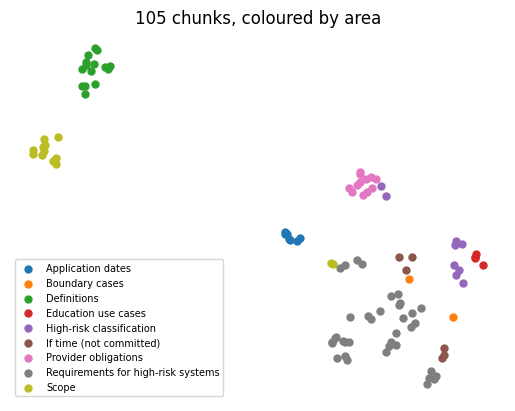

In [14]:
import umap, matplotlib.pyplot as plt
xy = umap.UMAP(n_neighbors=10, random_state=42).fit_transform(vectors)
for area in sorted({c["area"] for c in chunks}):
    pts = xy[[c["area"] == area for c in chunks]]
    plt.scatter(pts[:, 0], pts[:, 1], s=25, label=area)
plt.legend(fontsize=7); plt.title("105 chunks, coloured by area"); plt.axis("off"); plt.show()

**Comment:** Chunks of the same area are close together. The definitions (green), the provider obligations (pink) and the application dates (blue) form their own groups. The education use cases (red) are next to the high-risk rules of Article 6 (purple), which refer to them. The requirements (grey) form one large group.

## The settings for `config/rag.yaml`

In [15]:
pd.DataFrame([
    {"setting": "embedding.model", "chosen": BEST_MODEL, "step": "6"},
    {"setting": "embedding.remove_before_embedding", "chosen": REMOVE_BEFORE_EMBEDDING, "step": "6b"},
    {"setting": "retrieval.dense_weight", "chosen": BEST_WEIGHT, "step": "6 (1.0 = dense only)"},
    {"setting": "bm25.remove", "chosen": CHOSEN, "step": "5 (used only if dense_weight < 1.0)"},
    {"setting": "retrieval.top_k", "chosen": TOP_K_CHOSEN, "step": "7"},
]).set_index("setting")

,chosen,step
setting,,
embedding.model,BAAI/bge-m3,6
embedding.remove_before_embedding,none,6b
retrieval.dense_weight,0.8,6 (1.0 = dense only)
bm25.remove,stopwords + jury,5 (used only if dense_weight < 1.0)
retrieval.top_k,8,7


## 12. Log the results in Weights & Biases
D6 asks for the scores on the `val` split to be logged in W&B. One run keeps the chosen settings, the scores of the chosen search (Recall@5 and Recall@8), every table of steps 4–7, the result of every val question and a chart for every step. The charts are also saved in one PDF, `docs/eval/embedding-results.pdf`, so the experiment card can link to both.

In [23]:

import hashlib, subprocess, wandb
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages

if isinstance(model, str):      # an earlier version of this cell overwrote the model of step 8; load it again
    model = SentenceTransformer(BEST_MODEL, device="cpu")

WANDB_PROJECT = "eliza-rag"
WANDB_ENTITY = None            # the team name in W&B, if the team has one; None = my own account
PDF_FILE = "../docs/eval/embedding-results.pdf" if IN_REPO else "embedding-results.pdf"

sha = lambda path: hashlib.sha256(open(P(path), "rb").read()).hexdigest()
try:
    commit = subprocess.run(["git", "rev-parse", "--short", "HEAD"], capture_output=True, text=True).stdout.strip()
except OSError:
    commit = ""
try:      # do not send the computer name, user name or folder paths to W&B
    settings = wandb.Settings(x_disable_meta=True, x_disable_stats=True, save_code=False)
except Exception:
    settings = wandb.Settings(save_code=False)

# ---- the figures (the same ones go to W&B and to the PDF) ----
METRICS = [f"Recall@{K}", f"Capped recall@{K}", "MRR", f"Precision@{K}"]
figures = {}

def bars(table, title, highlight):
    """Grouped bar chart: one group per row of the table, one bar per metric; the chosen row is in bold."""
    fig, ax = plt.subplots(figsize=(10, 4.5))
    x = np.arange(len(table)); width = 0.2
    for n, m in enumerate(METRICS):
        ax.bar(x + (n - 1.5) * width, table[m], width, label=m)
    ax.set_xticks(x); ax.set_xticklabels(table.index, rotation=20, ha="right")
    for label in ax.get_xticklabels():
        if label.get_text() == highlight: label.set_fontweight("bold")
    ax.set_ylim(0, 1); ax.set_ylabel("score on the val questions"); ax.set_title(title); ax.legend(ncol=4, fontsize=8)
    ax.grid(axis="y", alpha=0.3); fig.tight_layout()
    return fig

# step 4: the jury's votes
votes = jury.set_index("word")[JURY + ["majority"]]
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.imshow((votes == "IGNORE").T.astype(int), cmap="RdYlGn_r", aspect="auto", vmin=0, vmax=1)
ax.set_xticks(range(len(votes))); ax.set_xticklabels(votes.index, rotation=45, ha="right")
ax.set_yticks(range(len(votes.columns))); ax.set_yticklabels(votes.columns)
ax.set_title("Step 4 · LLM jury: red = IGNORE, green = KEEP"); fig.tight_layout()
figures["step4_jury_votes"] = fig

# step 5: word removal for BM25
figures["step5_bm25_word_removal"] = bars(test, "Step 5 · BM25: which words to remove", CHOSEN)

# step 6: Recall@8 of every model and dense weight (model_name, so that `model` of step 8 is not overwritten)
fig, ax = plt.subplots(figsize=(10, 4.5))
for model_name, part in searches.iloc[1:].groupby("model"):
    ax.plot(part["dense weight"], part[f"Recall@{K}"], marker="o", label=model_name, linewidth=3 if model_name == short_name(BEST_MODEL) else 1.5)
ax.axhline(searches.iloc[0][f"Recall@{K}"], color="grey", linestyle="--", label="BM25 alone")
ax.set_xlabel("dense weight (0.5 = equal mix with BM25, 1.0 = embedding only)"); ax.set_ylabel(f"Recall@{K}")
ax.set_title(f"Step 6 · embedding models and BM25 weight (chosen: {short_name(BEST_MODEL)}, {BEST_WEIGHT})")
ax.grid(alpha=0.3); ax.legend(fontsize=8); fig.tight_layout()
figures["step6_models_and_weights"] = fig

# step 6: the best weight of every model, all four metrics
best_rows = searches.iloc[1:].sort_values([f"Recall@{K}", "MRR"], ascending=False).groupby("model").head(1)
best_rows = best_rows.assign(label=best_rows["model"] + " (" + best_rows["dense weight"].astype(str) + ")").set_index("label")
figures["step6_best_of_each_model"] = bars(best_rows[METRICS], "Step 6 · each model with its best weight",
                                           f"{short_name(BEST_MODEL)} ({BEST_WEIGHT})")

# step 6b: word removal before embedding
figures["step6b_removal_before_embedding"] = bars(compare, "Step 6b · removing words before embedding", "full text")

# step 7: top-k
fig, ax = plt.subplots(figsize=(7, 4.5))
for m in ["Recall", "Capped recall", "MRR", "Precision"]:
    ax.plot(topk["top-k"], topk[m], marker="o", label=m)
ax.axvline(TOP_K_CHOSEN, color="grey", linestyle="--")
ax.set_xticks(topk["top-k"]); ax.set_xlabel("chunks returned (top-k)"); ax.set_ylim(0, 1)
ax.set_title(f"Step 7 · how many chunks (chosen: {TOP_K_CHOSEN})"); ax.grid(alpha=0.3); ax.legend(fontsize=8); fig.tight_layout()
figures["step7_top_k"] = fig

# step 10: every val question with the chosen search
rows = []
for q in dev:
    gold = set(q["gold_ids"].split(";"))
    found = [c.split("#")[0] for c in search(q["question"])]
    rows.append({"id": q["id"], "question": q["question"], "gold": q["gold_ids"], "found": ";".join(found),
                 "hits": len(gold & set(found)), "gold count": len(gold),
                 f"recall@{TOP_K_CHOSEN}": round(len(gold & set(found)) / len(gold), 2)})
per_question = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(per_question["id"], per_question[f"recall@{TOP_K_CHOSEN}"], color="tab:blue")
for x, (h, g) in enumerate(zip(per_question["hits"], per_question["gold count"])):
    ax.text(x, 0.02, f"{h}/{g}", ha="center", fontsize=7, color="white", rotation=90)
ax.set_ylim(0, 1); ax.set_ylabel(f"Recall@{TOP_K_CHOSEN}"); ax.tick_params(axis="x", rotation=90)
ax.set_title(f"Step 10 · every val question with the chosen search (found / gold provisions)"); fig.tight_layout()
figures["step10_val_questions"] = fig

# step 11: UMAP
fig, ax = plt.subplots(figsize=(8, 6))
for area in sorted({c["area"] for c in chunks}):
    pts = xy[[c["area"] == area for c in chunks]]
    ax.scatter(pts[:, 0], pts[:, 1], s=25, label=area)
ax.legend(fontsize=7, loc="best"); ax.set_title("Step 11 · 105 chunks, coloured by area"); ax.axis("off"); fig.tight_layout()
figures["step11_umap"] = fig

# ---- all figures in one PDF, the first page with the chosen settings and the final scores ----
final_5, final_k = score(search, 5), score(search, TOP_K_CHOSEN)
with PdfPages(PDF_FILE) as pdf:
    fig = plt.figure(figsize=(10, 4.5)); fig.text(0.05, 0.9, "ELIZA · embedding experiment on the val split (KAN-97, KAN-221, KAN-99)", fontsize=14, weight="bold")
    lines = [f"Val questions scored: {len(dev)}",
             f"Embedding model: {BEST_MODEL}   dense weight: {BEST_WEIGHT}   BM25 words removed: {CHOSEN}",
             f"Words removed before embedding: {REMOVE_BEFORE_EMBEDDING}   top-k: {TOP_K_CHOSEN}",
             "Final search, top 5: " + ", ".join(f"{k} {v}" for k, v in final_5.items()),
             f"Final search, top {TOP_K_CHOSEN}: " + ", ".join(f"{k} {v}" for k, v in final_k.items()),
             f"Test split SHA-256: {sha('../docs/eval/eval-set-v1-test.csv')[:16]}…   commit: {commit}"]
    for n, line in enumerate(lines):
        fig.text(0.05, 0.75 - n * 0.11, line, fontsize=10)
    pdf.savefig(fig); plt.close(fig)
    for f in figures.values():
        pdf.savefig(f)
print("Saved", PDF_FILE, "with", len(figures) + 1, "pages")

# ---- Weights & Biases ----
wandb.login()
run = wandb.init(project=WANDB_PROJECT, entity=WANDB_ENTITY, name="E1-retrieval-val-k8", job_type="retrieval",
                 tags=["sprint-2", "baseline", "val", "recall@8"], settings=settings, config={
    "chosen": {"embedding_model": BEST_MODEL, "dense_weight": BEST_WEIGHT, "bm25_remove": CHOSEN,
               "remove_before_embedding": REMOVE_BEFORE_EMBEDDING, "top_k": TOP_K_CHOSEN},
    "tried": {"embedding_models": EMBEDDING_MODELS, "dense_weights": DENSE_WEIGHTS, "top_k": TOP_K,
              "word_removal": list(REMOVE), "jury": JURY},
    "rag_yaml": CONFIG, "val_questions_scored": len(dev), "chunks": len(chunks),
    "corpus_sha256": sha("../data/" + CONFIG["chunking"]["source_file"]),
    "test_split_sha256": sha("../docs/eval/eval-set-v1-test.csv"), "git_commit": commit,
})
wandb.log({**{"final/" + k: v for k, v in final_5.items()}, **{"final/" + k: v for k, v in final_k.items()}})
wandb.log({"tables/step4_jury": wandb.Table(dataframe=jury.astype(str)),
           "tables/step5_bm25_word_removal": wandb.Table(dataframe=test.reset_index()),
           "tables/step6_models_and_weights": wandb.Table(dataframe=searches),
           "tables/step6_recall5": wandb.Table(dataframe=recall5),
           "tables/step6b_removal_before_embedding": wandb.Table(dataframe=compare.reset_index()),
           "tables/step7_top_k": wandb.Table(dataframe=topk),
           "tables/val_questions": wandb.Table(dataframe=per_question)})
wandb.log({"charts/" + name: wandb.Image(f) for name, f in figures.items()})
artifact = wandb.Artifact("embedding-results", type="report"); artifact.add_file(PDF_FILE); run.log_artifact(artifact)
for f in figures.values():
    plt.close(f)
print("Logged:", final_5, final_k)
print("Run:", run.url)
wandb.finish()


Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

Saved ../docs/eval/embedding-results.pdf with 9 pages


/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results


wandb: Enter your choice: 2


wandb: You chose 'Use an existing W&B account'
wandb: Logging into https://api.wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: Create a new API key at: https://wandb.ai/authorize?ref=models
wandb: Store your API key securely and do not share it.


wandb: Paste your API key and hit enter: ··········


wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin


Logged: {'Recall@5': np.float64(0.43), 'Capped recall@5': np.float64(0.47), 'MRR': np.float64(0.6), 'Precision@5': np.float64(0.24)} {'Recall@8': np.float64(0.59), 'Capped recall@8': np.float64(0.61), 'MRR': np.float64(0.61), 'Precision@8': np.float64(0.2)}
Run: https://wandb.ai/gozdenur104-metu-middle-east-technical-university/eliza-rag/runs/v7g5hhxh


final/Capped recall@5,▁
final/Capped recall@8,▁
final/MRR,▁
final/Precision@5,▁
final/Precision@8,▁
final/Recall@5,▁
final/Recall@8,▁
final/Capped recall@5,0.47
final/Capped recall@8,0.61
final/MRR,0.61
final/Precision@5,0.24


## Next (KAN-99)
- Compare the answers without and with retrieval, log them in Weights & Biases next to this run (D6), and fill in the experiment card.
- Compare bge-m3 and bge-large again when there are more `val` questions (D8): they are close, and the winner depends on the number of chunks.
- Add the instructor's RAG metrics (Context Entities Recall, Faithfulness).
- For questions that need many provisions, try **query decomposition** (split the question into smaller ones) or **MMR** (pick chunks that are relevant and different from each other, Carbonell & Goldstein 1998).